Epoch 1/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 19s 74ms/step - accuracy: 0.8201 - loss: 0.5163 - val_accuracy: 0.8537 - val_loss: 0.4091
Epoch 2/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 18s 75ms/step - accuracy: 0.8727 - loss: 0.3559 - val_accuracy: 0.8837 - val_loss: 0.3263
Epoch 3/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - accuracy: 0.8866 - loss: 0.3117 - val_accuracy: 0.8908 - val_loss: 0.3037
Epoch 4/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 18s 75ms/step - accuracy: 0.8959 - loss: 0.2913 - val_accuracy: 0.8925 - val_loss: 0.2980
Epoch 5/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 18s 75ms/step - accuracy: 0.9013 - loss: 0.2718 - val_accuracy: 0.8982 - val_loss: 0.2777
Epoch 6/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 3481s 15s/step - accuracy: 0.9068 - loss: 0.2560 - val_accuracy: 0.9054 - val_loss: 0.2643
Epoch 7/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.9099 - loss: 0.2426 - val_accuracy: 0.9058 - val_loss: 0.2574
Epoch 8/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 13s 55ms/step - accuracy: 0.9166 - loss: 0.2267 -

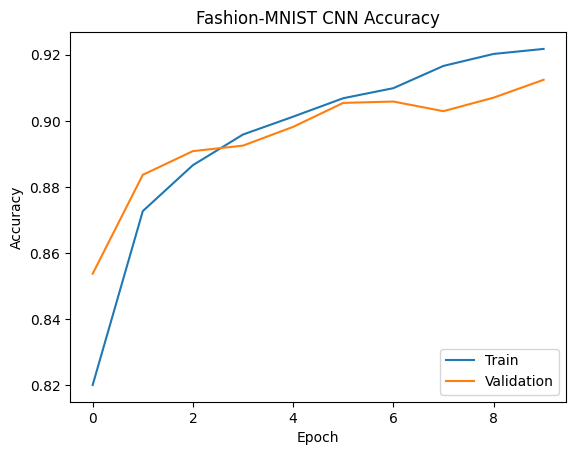

In [2]:
from keras.datasets import fashion_mnist
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from keras.utils import to_categorical

import numpy as np
import matplotlib.pyplot as plt

img_rows = 28
img_cols = 28
num_classes = 10

seed = 123
np.random.seed(seed)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train.reshape(
    X_train.shape[0],
    img_rows,
    img_cols,
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    img_rows,
    img_cols,
    1
)

y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

def cnn_model():

    model = Sequential()
    model.add(
        Conv2D(
            64,
            kernel_size=(5, 5),
            padding='valid',
            strides=(1, 1),
            input_shape=(img_rows, img_cols, 1),
            activation='relu'
        )
    )

    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.5))
    model.add(Flatten())
    model.add(Dense(127,activation='relu'))
    model.add(Dense(num_classes,activation='softmax'))

    # 모델 컴파일
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy'])
    return model

model = cnn_model()

disp = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=200,
    verbose=1
)

scores = model.evaluate(X_test,y_test,verbose=0)
print("loss : %.2f" % scores[0])
print("accuracy : %.2f" % scores[1])

plt.plot(disp.history['accuracy'])
plt.plot(disp.history['val_accuracy'])
plt.title('Fashion-MNIST CNN Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'],loc='lower right')
plt.show()
